# Assignment - Supervised Learning flow

# Part 1(a) Student details:
#### Yosef Y. 4740

## Part 1(b) - Chat-GPT/other AI-agent/other assistance used:


<pre>   
AI agent name: ChatGPT  
Goal: Get explanations about logistic regression, hyperparameters, and Python functions.  

Prompt1: "תן לי הסבר מפורט על ההיפר פרמטרים של רגרסיה לוגיסטית"  
Prompt2: "תסביר לי לגבי סוגים שונים של אלגוריתמים של רגרסיה לוגיסטית"  
Prompt3: "מה נחשב המחלקה הראשית במידע שלי"  

Note: General explanations on how to write different functions in Python.    
</pre>

## Part 1(c) - Learning Problem and dataset explaination.


<pre>
In this assignment we use the historical dataset of Titanic passengers. This is a binary classification problem, where the goal is to predict whether a passenger survived or not. The prediction is based on different features such as age, gender, ticket class, number of relatives on board, ticket price, and more.



    
</pre>

## Part 2 - Initial Preparations 


In [1]:
import pandas as pd

train = pd.read_csv("titanic_train.csv")
test = pd.read_csv("titanic_test.csv")

print("First 5 rows of the training set:")
display(train.head())

print("First 5 rows of the test set:")
display(test.head())


First 5 rows of the training set:


,Pclass,Sex,Age,SibSp,Parch,Fare,Embarked,Survived
0,1,0,54.0,1,0,78.2667,1,1
1,2,0,45.0,0,0,13.5000,0,1
2,3,1,20.0,0,0,9.5000,0,0
3,3,1,36.0,0,0,7.8958,0,0
4,3,1,22.0,0,0,8.0500,0,0


First 5 rows of the test set:


,Pclass,Sex,Age,SibSp,Parch,Fare,Embarked,Survived
0,3,1,35.000000,0,0,7.0500,0,0
1,3,1,30.000000,0,0,7.2500,0,0
2,3,1,29.699118,0,0,14.5000,0,0
3,3,0,21.000000,0,0,7.7500,2,0
4,3,1,32.000000,0,0,56.4958,0,1


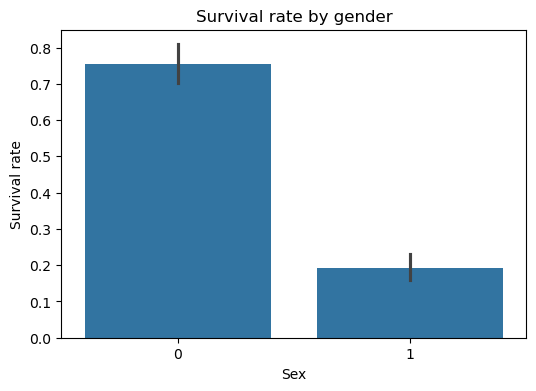

In [2]:
import matplotlib.pyplot as plt
import seaborn as sns

# Survival rate by gender
plt.figure(figsize=(6,4))
sns.barplot(x="Sex", y="Survived", data=train)
plt.title("Survival rate by gender")
plt.ylabel("Survival rate")
plt.show()

<p>
The bar chart shows that about 75% of women survived, while only around 20% of men did.
This highlights a very strong correlation between gender and survival, where women had a clear advantage.
</p>


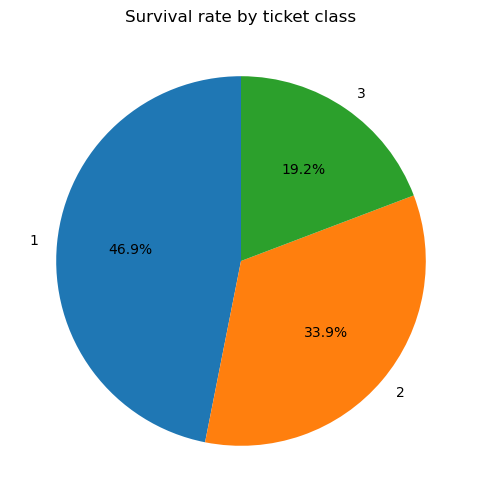

In [3]:
# Survival rate by ticket class 
survival_by_class = train.groupby("Pclass")["Survived"].mean()

plt.figure(figsize=(6,6))
plt.pie(survival_by_class, labels=survival_by_class.index, autopct="%1.1f%%", startangle=90)
plt.title("Survival rate by ticket class")
plt.show()


<p>
This pie chart shows survival rates by ticket class. Passengers in first class survived the most, while third-class passengers had the lowest survival.
</p>


## Part 3 - Experiments


In [4]:
import pandas as pd
from sklearn.model_selection import GridSearchCV
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.metrics import make_scorer, f1_score
from sklearn.linear_model import LogisticRegression

In [5]:
# Separate features and target
X_train = train.drop("Survived", axis=1)
y_train = train["Survived"]             


In [6]:
# Define quality metric: F1 score for the majority class
# (class 0 = did not survive)
f1_majority = make_scorer(f1_score, pos_label=0)

In [7]:
# Build pipeline: optional scaling + logistic regression model
pipe = Pipeline([
    ("scaler", StandardScaler()),                   
    ("model", LogisticRegression(max_iter=1000, solver="lbfgs"))  # lbfgs supports: L2 and None
])

In [8]:
# Define parameter grid: 
param_grid = [{
        "scaler": [StandardScaler(), None],   # feature engineering: with or without scaling
        "model": [LogisticRegression(max_iter=1000, solver="lbfgs")],
        "model__C": [0.1, 1.0],               # hyperparameter 1: regularization strength
        "model__penalty": ["l2", None]        # hyperparameter 2: type of penalty 
    }]

In [9]:
# Run Grid Search with 5 fold Cross Validation
grid_search = GridSearchCV (
    estimator = pipe,
    param_grid = param_grid,
    scoring = f1_majority,   # evaluation metric
    cv = 5,                  # 5 fold cross validation
    n_jobs = -1              # use all cores for faster computation
    )

grid_search.fit(X_train, y_train)

GridSearchCV(cv=5,
             estimator=Pipeline(steps=[('scaler', StandardScaler()),
                                       ('model',
                                        LogisticRegression(max_iter=1000))]),
             n_jobs=-1,
             param_grid=[{'model': [LogisticRegression(max_iter=1000)],
                          'model__C': [0.1, 1.0],
                          'model__penalty': ['l2', None],
                          'scaler': [StandardScaler(), None]}],
             scoring=make_scorer(f1_score, response_method='predict', pos_label=0))

In [10]:
# Collect and display results of all configurations
results = pd.DataFrame(grid_search.cv_results_)

results = results[[
    "params",
    "mean_test_score",    # average F1 across 5 folds
    "std_test_score",     # variability between folds
    "rank_test_score"     # rank (1 = best)
]]

print("All results sorted by best score:")
display(results.sort_values(by="mean_test_score", ascending=False))

All results sorted by best score:


,params,mean_test_score,std_test_score,rank_test_score
1,"{'model': LogisticRegression(max_iter=1000), '...",0.841711,0.027835,1
0,"{'model': LogisticRegression(max_iter=1000), '...",0.840341,0.023606,2
5,"{'model': LogisticRegression(max_iter=1000), '...",0.840121,0.024179,3
4,"{'model': LogisticRegression(max_iter=1000), '...",0.838862,0.024853,4
2,"{'model': LogisticRegression(max_iter=1000), '...",0.837203,0.022393,5
3,"{'model': LogisticRegression(max_iter=1000), '...",0.837203,0.022393,5
6,"{'model': LogisticRegression(max_iter=1000), '...",0.837203,0.022393,5
7,"{'model': LogisticRegression(max_iter=1000), '...",0.837203,0.022393,5


In [11]:
# Display best configuration and its score
best_params = grid_search.best_params_
best_score = grid_search.best_score_

print("\nBest configuration:")
for param, value in best_params.items():
    print(f"  {param}: {value}")

print(f"\nBest F1 score: **{best_score:.3f}**")



Best configuration:
  model: LogisticRegression(max_iter=1000)
  model__C: 0.1
  model__penalty: l2
  scaler: None

Best F1 score: **0.842**


## Part 4 - Training 


In [12]:
# Extract the best configuration from grid search
best_params = grid_search.best_params_

print("Best configuration found:", best_params)



Best configuration found: {'model': LogisticRegression(max_iter=1000), 'model__C': 0.1, 'model__penalty': 'l2', 'scaler': None}


In [13]:
# Train final model with the best configuration on the full training set
final_pipeline = Pipeline([
    ("scaler", best_params["scaler"]),   
    ("model", LogisticRegression(        
        C=best_params["model__C"],       
        penalty=best_params["model__penalty"],  
        solver="lbfgs",                  
        max_iter=1000,                   
    ))
])

# Fit the final model on the entire training set
final_pipeline.fit(X_train, y_train)
print("Final model trained successfully on the entire training set.")


Final model trained successfully on the entire training set.


## Part 5 - Apply on test and show model performance estimation

In [14]:
# Separate features and target in the test set
X_test = test.drop("Survived", axis=1)
y_test = test["Survived"]

In [15]:
# Prediction on the test set

y_pred = final_pipeline.predict(X_test)

results_df = X_test.copy()
results_df["True_Survived"] = y_test.values
results_df["Predicted_Survived"] = y_pred

# Show the first 5 rows with predictions
results_df.head()


,Pclass,Sex,Age,SibSp,Parch,Fare,Embarked,True_Survived,Predicted_Survived
0,3,1,35.000000,0,0,7.0500,0,0,0
1,3,1,30.000000,0,0,7.2500,0,0,0
2,3,1,29.699118,0,0,14.5000,0,0,0
3,3,0,21.000000,0,0,7.7500,2,0,1
4,3,1,32.000000,0,0,56.4958,0,1,0


In [16]:
# Model Performance Evaluation

from sklearn.metrics import f1_score

test_f1 = f1_score(y_test, y_pred, average="binary")

print(f"Model performance on the test set (F1 score): {test_f1:.3f}")


Model performance on the test set (F1 score): 0.701
